# Computing interval multiplicities and splittings

A finite encoding retains spaces and maps, so we can ask whether a proposed piece actually splits off. We will construct a square module, recover its interval multiplicities, and request maps that reconstruct it. Then a branching example will show what a non-interval residual means.

You need TamerOp and CairoMakie, and familiarity with matrices and [finite modules](../spaces_and_maps.md). The [mathematical lesson](../decomposition.md) explains summands; the [API reference](../src/reference/decomposition.md) gives the exact contracts. All algebra here is rational on the declared finite poset. Direct diagrams are legitimate inputs; a point cloud is not required.


In [1]:
import TamerOp as OP
using CairoMakie
A = OP.Advanced
QQ = Rational{BigInt}
field = OP.CoreModules.QQField();


TamerOp.CoreModules.CoeffFields.QQField()

## Start with pieces we can recognize

The square has vertices 1 (bottom), 2 and 3 (middle), and 4 (top). Its module is a sum of the full square, the upper edge `{2,4}`, and two copies supported only at 4. The coordinates below name those copies, so the expected multiplicities are known before we run a decomposition. In an independently supplied module the coordinates need not reveal them.


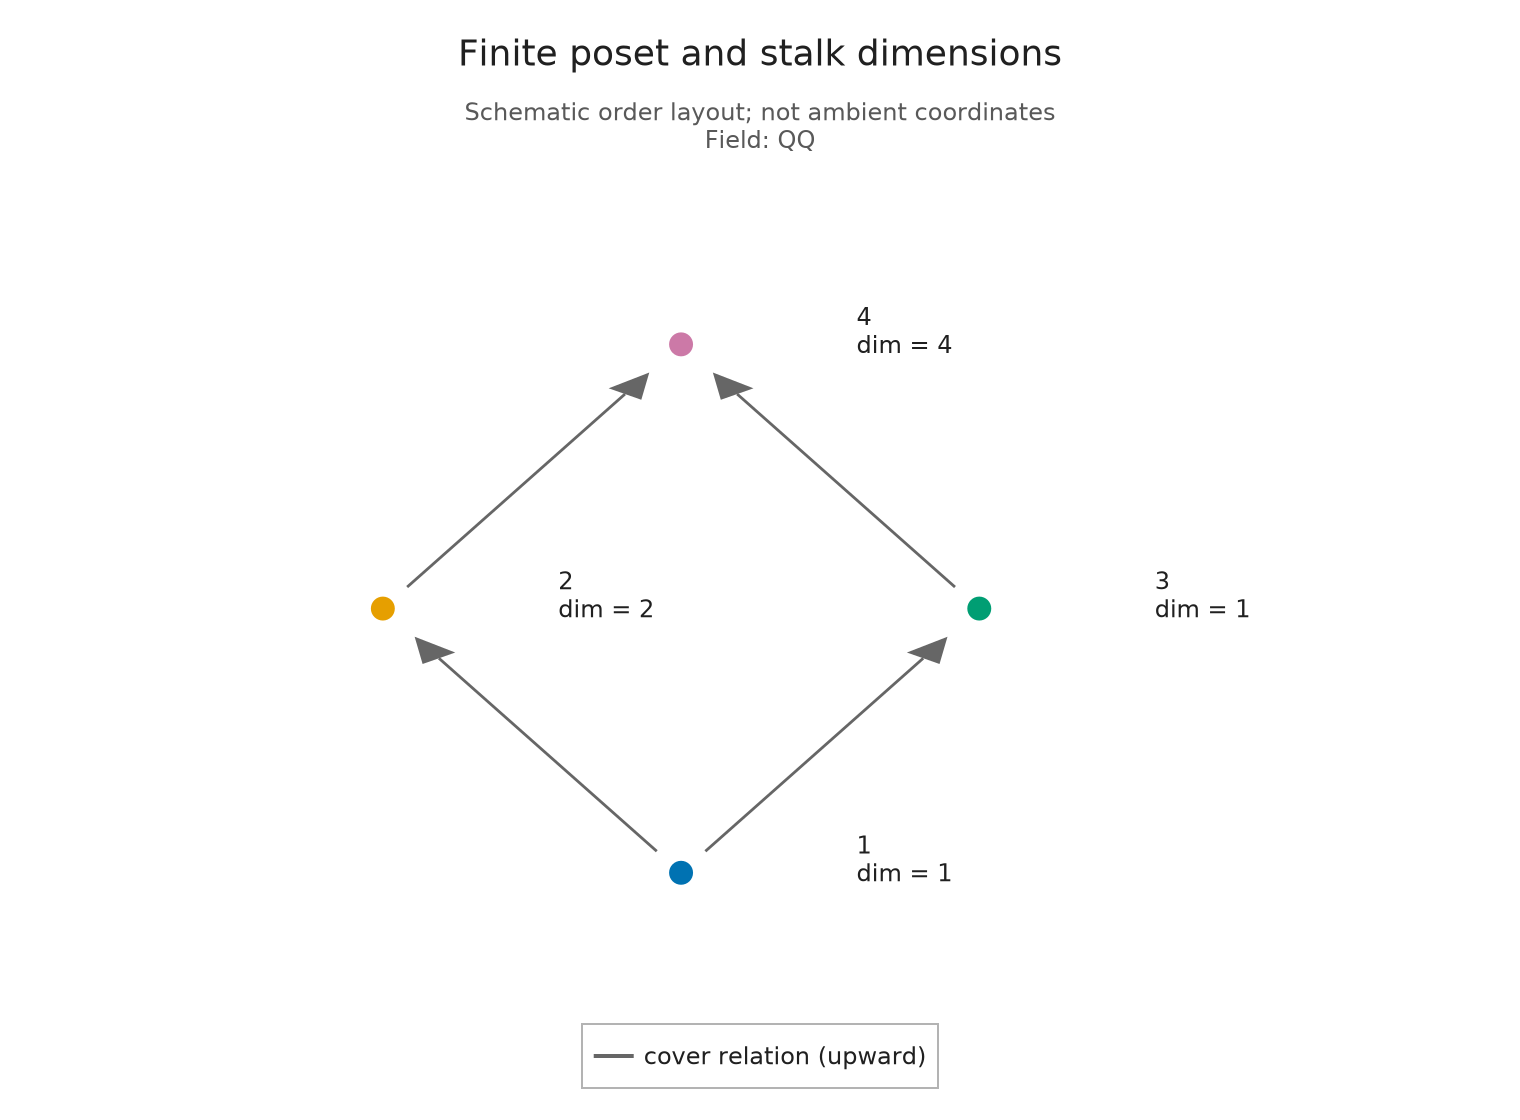

In [2]:
P = A.ProductOfChainsPoset((2, 2))
supports = [[1, 2, 3, 4], [2, 4], [4], [4]]
active = [findall(I -> v in I, supports) for v in 1:4]
maps = Dict((u, v) => QQ[i == j for i in active[v], j in active[u]]
            for (u, v) in A.cover_edges(P))
M = A.PModule{QQ}(P, length.(active), maps; field)
@assert OP.dimensions(M).stalks == [1, 2, 1, 4]
OP.visualize(M)


## Ask for one multiplicity

The first call asks how many sink-only intervals split off the **whole** module. The generalized-rank call instead looks only at the sink stalk. Its answer includes the two other summands that also reach vertex 4.


In [3]:
multiplicity = OP.interval_multiplicity(M; vertices=[4])
restricted_rank = OP.generalized_rank(M; vertices=[4])
@assert multiplicity == 2
@assert restricted_rank == 4
(; multiplicity, restricted_rank)


(multiplicity = 2, restricted_rank = 4)

## Choose the scope of the search

A chosen family gives exact answers for those supports. Its residual may contain unqueried intervals: `missing` means that the global decomposability question is still undecided. A complete search first prunes impossible supports with top/socle endpoint data. The default result retains counts and residual dimensions.


In [4]:
selected = OP.interval_decomposition(M; family=[[4]])
@assert ismissing(OP.is_interval_decomposable(selected))
@assert A.residual_dimensions(selected) == [1, 2, 1, 2]
whole = OP.interval_decomposition(M)
@assert A.interval_family(whole) == [[1, 2, 3, 4], [2, 4], [4]]
@assert A.interval_multiplicities(whole) == [1, 1, 2]
@assert OP.is_interval_decomposable(whole) === true
OP.describe(whole)


(kind = :interval_decomposition, category = :finite_poset_representations, field = TamerOp.CoreModules.CoeffFields.QQField(), vertices = 4, interval_types = 3, interval_copies = 4, residual_dimension = 0, exhaustive = true, interval_decomposable = true, witnesses = false, search = (scanned = 3, candidates = 3, tested = 3))

## Recover a splitting in the supplied coordinates

Request witnesses when we need actual modules and maps. For the selected sink-only interval, `inclusion` inserts its two copies and `projection` extracts them. The other two intervals form the residual. The displayed matrix at vertex 4 is the computed projection; its source and target dimensions are 4 and 2.


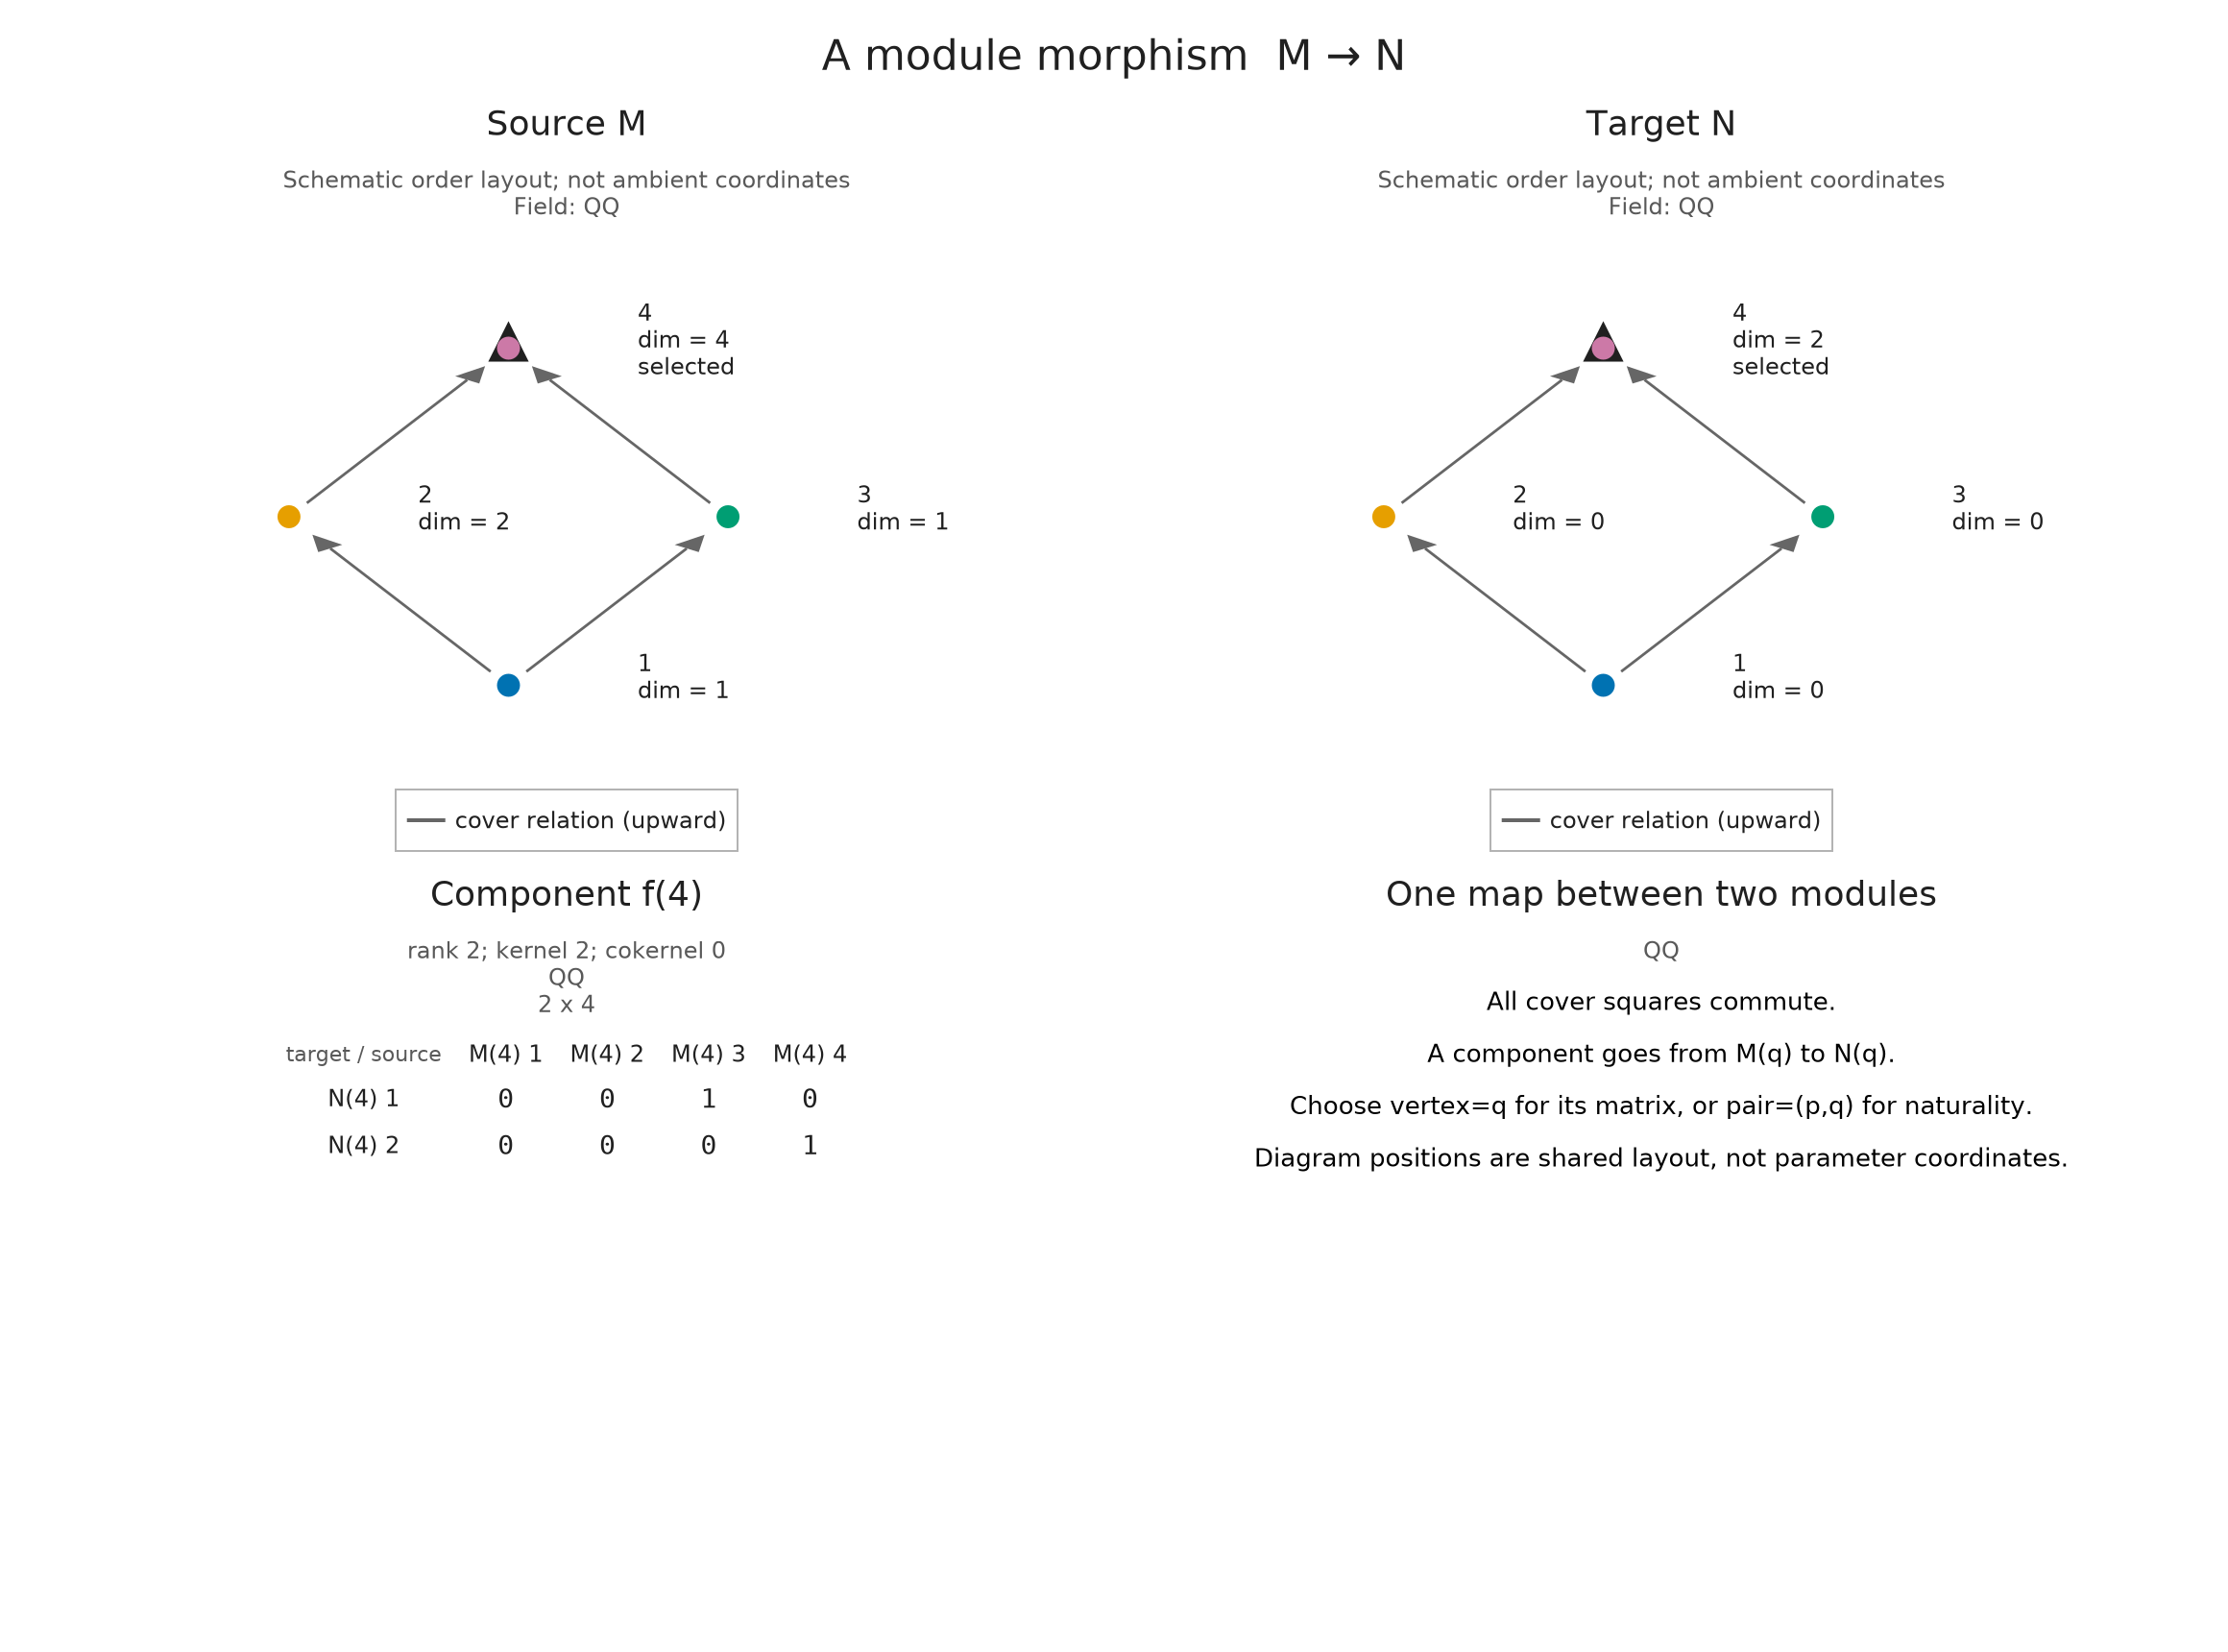

In [5]:
split = OP.interval_decomposition(M; family=[[4]], witnesses=true)
w = A.decomposition_maps(split)
@assert A.check_interval_decomposition(split; throw=true).splitting_checked
@assert OP.dimensions(w.summand).stalks == [0, 0, 0, 2]
@assert OP.dimensions(w.residual).stalks == [1, 2, 1, 2]
OP.visualize(w.projection; vertex=4)


The reconstruction identity is stronger than matching dimensions. At every vertex, the interval and residual idempotents add to the identity. The validator also checks naturality on every cover, both retractions and the mixed zero composites.


In [6]:
using LinearAlgebra
for v in 1:4
    i = A.component(w.inclusion, v)
    p = A.component(w.projection, v)
    j = A.component(w.residual_inclusion, v)
    q = A.component(w.residual_projection, v)
    @assert i * p + j * q == Matrix{QQ}(LinearAlgebra.I, OP.dimensions(M, v).stalk, OP.dimensions(M, v).stalk)
end
OP.describe(split)


(kind = :interval_decomposition, category = :finite_poset_representations, field = TamerOp.CoreModules.CoeffFields.QQField(), vertices = 4, interval_types = 1, interval_copies = 2, residual_dimension = 6, exhaustive = false, interval_decomposable = missing, witnesses = true, search = (scanned = 1, candidates = 1, tested = 1))

## See a residual that contains no intervals

Three incomparable sources map into a two-dimensional sink along three distinct lines. No interval copy admits a retraction. A complete search therefore returns `false`, and the residual is the entire module. This is an algebraic statement about these maps; a nonempty support picture alone could not establish it.


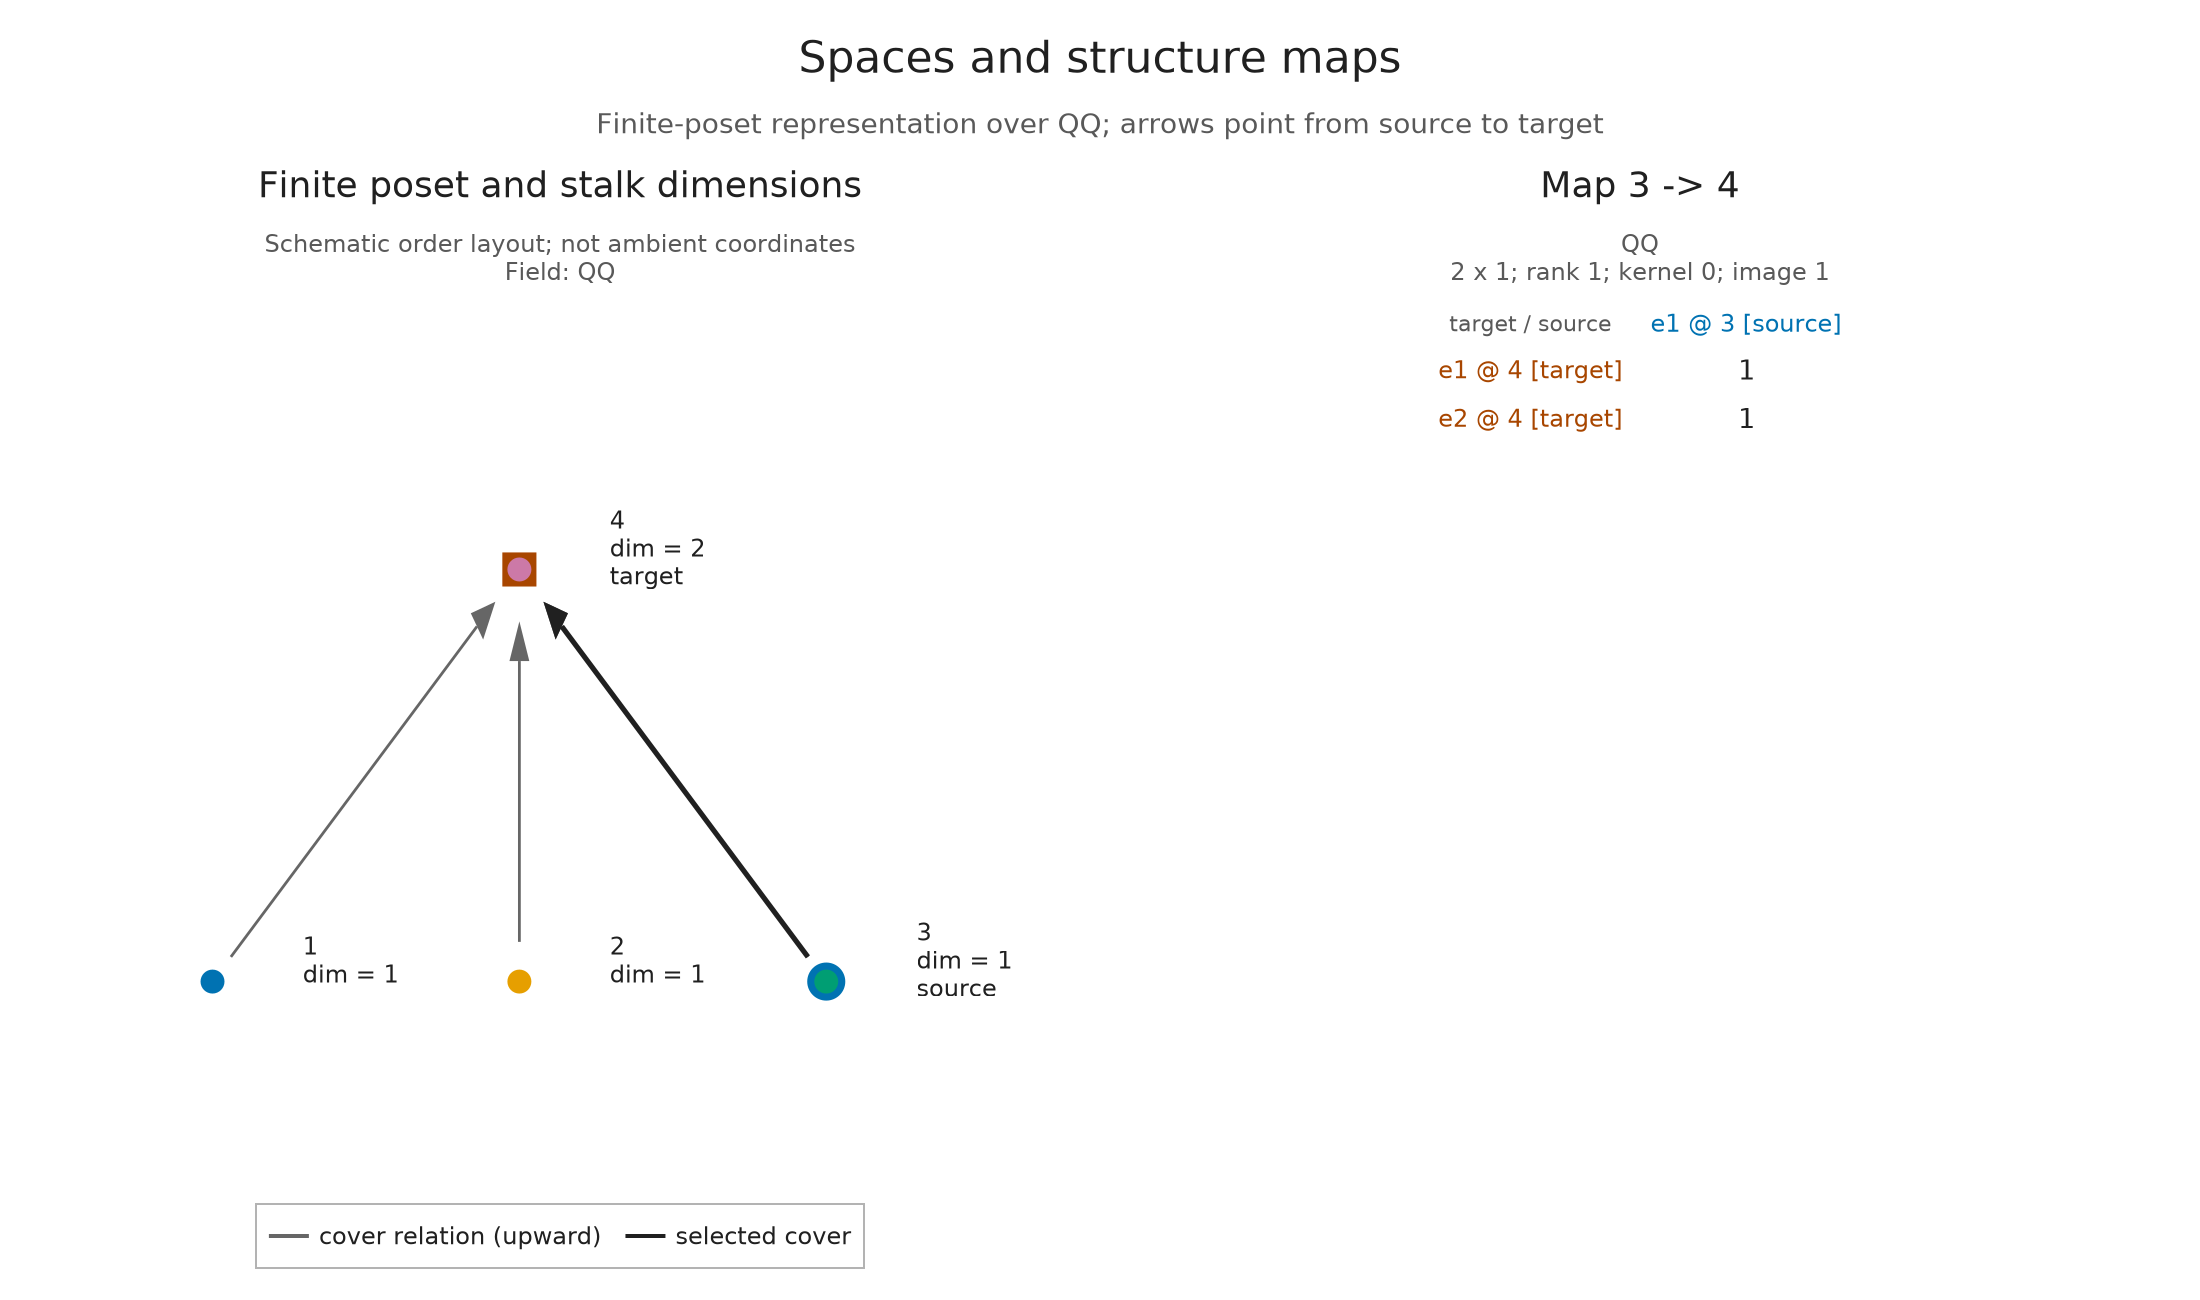

In [7]:
star = A.FinitePoset(Bool[1 0 0 1; 0 1 0 1; 0 0 1 1; 0 0 0 1])
three_lines = A.PModule{QQ}(star, [1, 1, 1, 2],
    Dict((1, 4) => reshape(QQ[1, 0], 2, 1),
         (2, 4) => reshape(QQ[0, 1], 2, 1),
         (3, 4) => reshape(QQ[1, 1], 2, 1)); field)
remainder = OP.interval_decomposition(three_lines; witnesses=true)
@assert OP.is_interval_decomposable(remainder) === false
@assert isempty(A.interval_multiplicities(remainder))
@assert A.residual_dimensions(remainder) == [1, 1, 1, 2]
OP.visualize(A.decomposition_maps(remainder).residual; kind=:module_inspector, pair=(3, 4))


## Use the same algebra after encoding

An `EncodingResult` also carries a classifier from original parameters into the finite base. For this grid, the interval labels still refer to finite vertices. The returned provenance records that category; it does not declare that the interval list is complete in a different ambient category. Filtered-data encodings can enter through the same calls.


In [8]:
classifier = A.GridEncodingMap(P, ([0, 1], [0, 1]))
encoded = OP.EncodingResult(P, M, classifier)
cache = OP.SessionCache()
@assert OP.interval_multiplicity(encoded; vertices=[4], cache) == 2
encoded_result = OP.interval_decomposition(encoded; cache)
@assert OP.is_interval_decomposable(encoded_result) === true
OP.provenance(encoded_result)


(category = :finite_poset_representations, base_poset = ProductOfChainsPoset(axes=(2, 2), orientation=(1, 1), nvertices=4), field = TamerOp.CoreModules.CoeffFields.QQField(), model = :hom_composition_pairing, candidate_pruning = :top_socle_degree_zero, exhaustive = true, ambient_identification = :not_asserted)

## Bound a search deliberately

Candidate enumeration can grow exponentially. Use a chosen family when that is the intended question, and explicit budgets when attempting a complete search. An exhausted budget raises an error; it does not become a claim that a module fails to decompose. Exact rational and prime fields are supported. Numerical near-splittings over floating coefficients are a different problem.


In [9]:
budget = A.IntervalDecompositionBudget(max_vertices=4, max_dimension=16,
    max_matrix_entries=1000, max_antichains=16, max_candidates=256)
@assert OP.is_interval_decomposable(M; budget) === true
A.interval_candidates(M; budget)


3-element Vector{Vector{Int64}}:
 [1, 2, 3, 4]
 [2, 4]
 [4]

## Optional: change the view without changing the answer

The palette affects only the drawing. Multiplicities, field and splitting equations remain the same.


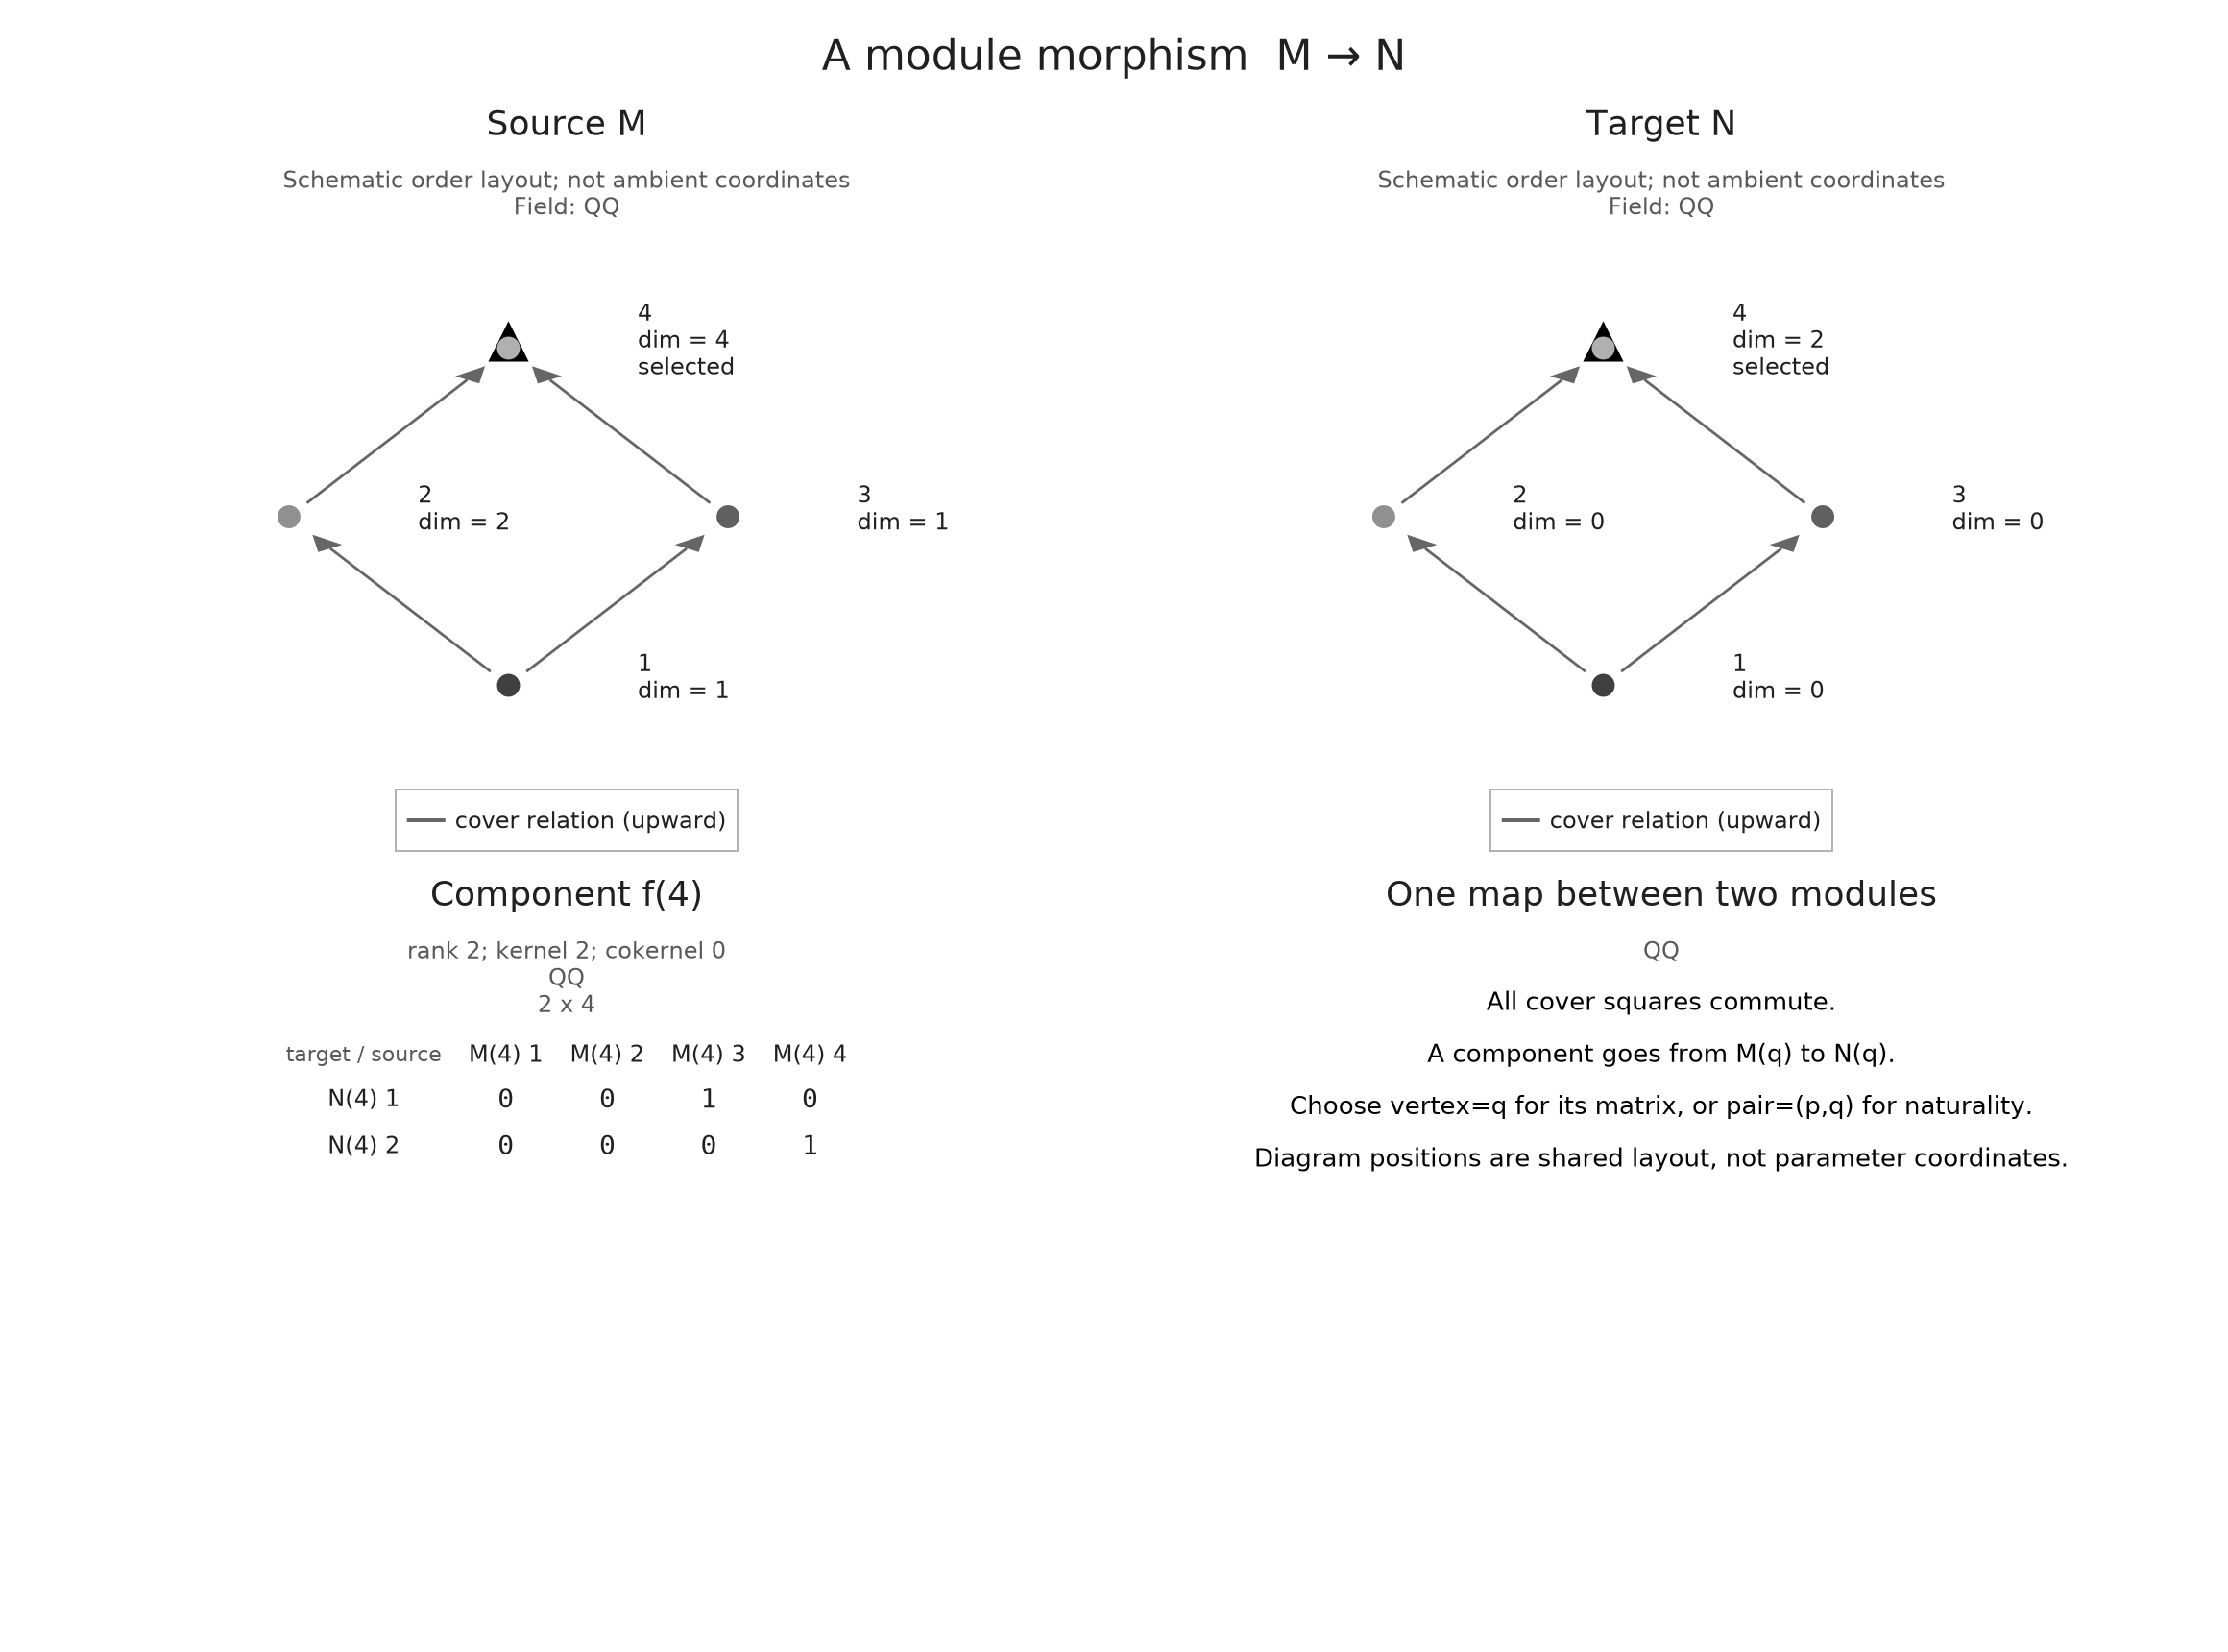

In [10]:
style = OP.VisualStyle(palette=:grayscale)
OP.visualize(w.projection; vertex=4, style)


## Continue with the algorithm

The [implementation account](../implementation/interval_decomposition.md) derives the composition pairing and the complete top/socle candidate search. For a different summary of the same finite object, [query generalized ranks](generalized_rank_queries.ipynb) and keep the restriction-versus-summand distinction visible.
